# 🛒 Supermarket Sales Analysis

## Objective
Analyze supermarket sales data to find useful information about **products, branches, categories, customers, payments, and ratings**, and derive actionable business insights.

### Business Questions
1. Which product generates the highest sales?
2. Which branch performs best?
3. Which category sells the most?
4. What is the most popular payment method?
5. Do Members spend more than Normal customers?
6. What is the average customer rating?

## Section 1: Setup & Data Loading

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Set visual style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 14

# Custom color palette
COLORS = ['#2196F3', '#FF5722', '#4CAF50', '#FFC107', '#9C27B0', '#00BCD4', '#E91E63', '#795548']

print('Libraries loaded successfully ✅')

Libraries loaded successfully ✅


In [2]:
# Load dataset
df = pd.read_excel('data/supermarket_sales.ods', engine='odf')
print(f'Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns')
df.head()

Dataset loaded: 500 rows × 13 columns


,Invoice ID,Date,Branch,City,Customer Type,Gender,Product,Category,Quantity,Unit Price,Payment,Rating,Sales
0,INV0001,2026-06-01,A,Jaipur,Member,Male,Milk,Dairy,4,57.13,UPI,3.8,228.52
1,INV0002,2026-02-26,A,Jaipur,Normal,Male,Rice,Grocery,9,66.85,Net Banking,3.9,601.65
2,INV0003,2026-02-09,C,Mumbai,Normal,Female,Milk,Dairy,3,57.28,Card,3.4,171.84
3,INV0004,2026-01-12,C,Mumbai,Member,Female,Shampoo,Personal Care,2,168.27,Card,4.5,336.54
4,INV0005,2026-06-30,A,Jaipur,Normal,Female,Apples,Fruits,5,130.57,Cash,3.1,652.85


## Section 2: Data Quality Check & Understanding

In [3]:
# Schema and data types
print('='*60)
print('SCHEMA OVERVIEW')
print('='*60)
print(f'\nShape: {df.shape}')
print(f'\nColumn Data Types:\n')
for col in df.columns:
    print(f'  {col:<20s} → {str(df[col].dtype):<20s} | {df[col].nunique()} unique values')

SCHEMA OVERVIEW

Shape: (500, 13)

Column Data Types:

  Invoice ID           → str                  | 500 unique values
  Date                 → datetime64[us]       | 173 unique values
  Branch               → str                  | 4 unique values
  City                 → str                  | 4 unique values
  Customer Type        → str                  | 2 unique values
  Gender               → str                  | 2 unique values
  Product              → str                  | 20 unique values
  Category             → str                  | 8 unique values
  Quantity             → int64                | 10 unique values
  Unit Price           → float64              | 488 unique values
  Payment              → str                  | 4 unique values
  Rating               → float64              | 21 unique values
  Sales                → float64              | 497 unique values


In [4]:
# Check for missing values and duplicates
print('='*60)
print('DATA QUALITY CHECK')
print('='*60)

null_counts = df.isnull().sum()
total_nulls = null_counts.sum()
dup_count = df.duplicated().sum()

print(f'\n✅ Total missing values: {total_nulls}')
print(f'✅ Duplicate rows: {dup_count}')

if total_nulls > 0:
    print('\n⚠️ Columns with missing values:')
    print(null_counts[null_counts > 0])
else:
    print('\n→ No missing values found. Dataset is clean.')

if dup_count > 0:
    print(f'\n⚠️ Found {dup_count} duplicate rows. Consider removing them.')
else:
    print('→ No duplicate rows found.')

DATA QUALITY CHECK

✅ Total missing values: 0
✅ Duplicate rows: 0

→ No missing values found. Dataset is clean.
→ No duplicate rows found.


In [5]:
# Verify Sales = Quantity × Unit Price
df['Sales_Check'] = df['Quantity'] * df['Unit Price']
mismatch = (df['Sales'] - df['Sales_Check']).abs() > 0.01
print(f'Sales formula verification (Sales = Quantity × Unit Price):')
print(f'  Mismatches: {mismatch.sum()} out of {len(df)} rows')
if mismatch.sum() == 0:
    print('  ✅ All sales values are correctly computed.')
df.drop(columns=['Sales_Check'], inplace=True)

Sales formula verification (Sales = Quantity × Unit Price):
  Mismatches: 0 out of 500 rows
  ✅ All sales values are correctly computed.


In [6]:
# Descriptive statistics for numeric columns
print('Descriptive Statistics (Numeric Features):\n')
df[['Quantity', 'Unit Price', 'Rating', 'Sales']].describe().round(2)

Descriptive Statistics (Numeric Features):



,Quantity,Unit Price,Rating,Sales
count,500.00,500.00,500.00,500.00
mean,5.54,88.66,3.99,488.82
std,2.88,57.28,0.57,437.33
min,1.00,27.67,3.00,28.61
25%,3.00,43.96,3.50,189.21
50%,5.50,61.88,4.00,335.91
75%,8.00,128.57,4.50,609.88
max,10.00,236.71,5.00,2114.82


### Observations — Data Quality
- **500 transactions**, **13 columns**, **zero missing values**, **zero duplicates** — the dataset is clean.
- **Sales** is correctly calculated as `Quantity × Unit Price` for all 500 rows.
- **4 branches** (A, B, C, D) mapped to **4 cities** (Jaipur, Delhi, Mumbai, Bengaluru).
- **20 unique products** grouped into **8 categories**.
- **4 payment methods**: UPI, Net Banking, Card, Cash.
- **Quantity** ranges from 1–10, **Unit Price** from ₹27.67–₹236.71, **Sales** from ₹28.61–₹2,114.82.
- **Ratings** range from 3.0–5.0 with an average of ~3.99.

## Section 3: Distribution of Key Features

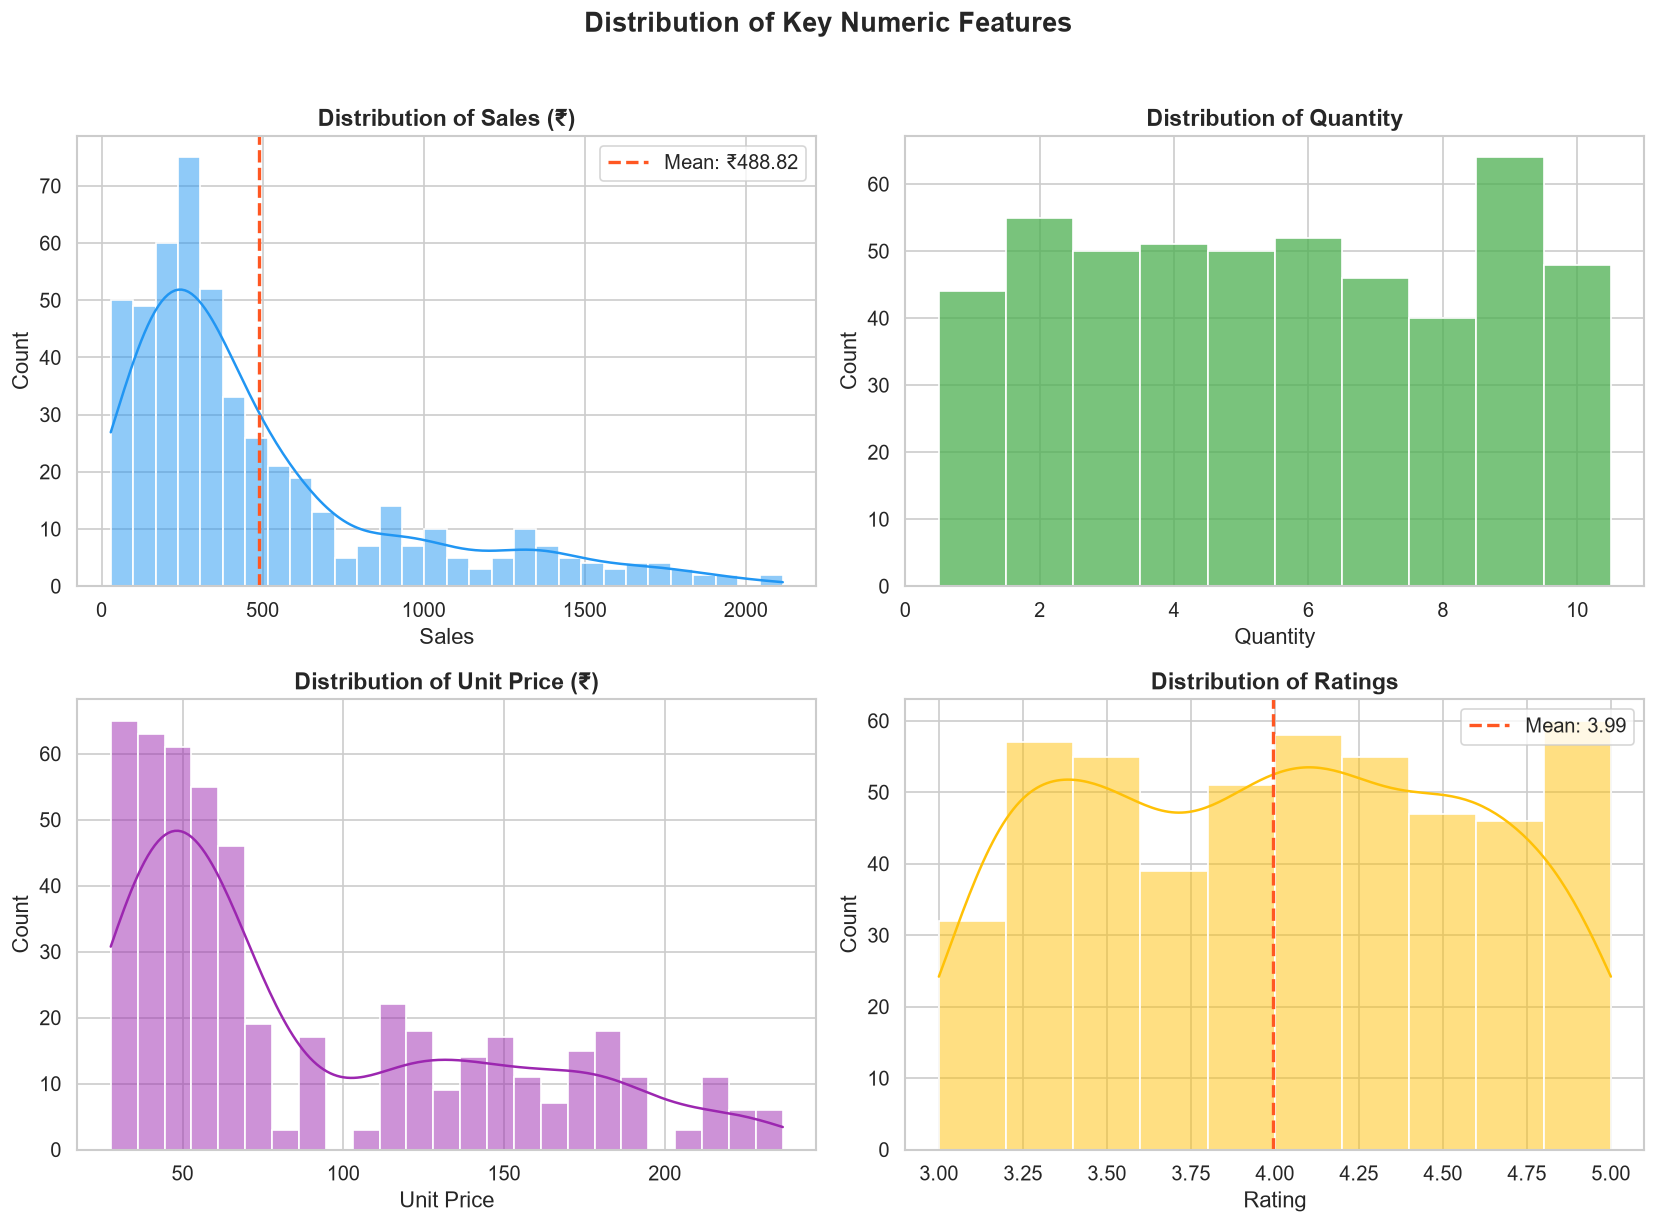

📊 Distributions plotted successfully.


In [7]:
# Distribution of numeric features
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Sales Distribution
sns.histplot(df['Sales'], bins=30, kde=True, color=COLORS[0], ax=axes[0, 0], edgecolor='white')
axes[0, 0].set_title('Distribution of Sales (₹)')
axes[0, 0].axvline(df['Sales'].mean(), color=COLORS[1], linestyle='--', linewidth=2, label=f'Mean: ₹{df["Sales"].mean():.2f}')
axes[0, 0].legend()

# Quantity Distribution
sns.histplot(df['Quantity'], bins=10, kde=False, color=COLORS[2], ax=axes[0, 1], edgecolor='white', discrete=True)
axes[0, 1].set_title('Distribution of Quantity')

# Unit Price Distribution
sns.histplot(df['Unit Price'], bins=25, kde=True, color=COLORS[4], ax=axes[1, 0], edgecolor='white')
axes[1, 0].set_title('Distribution of Unit Price (₹)')

# Rating Distribution
sns.histplot(df['Rating'], bins=10, kde=True, color=COLORS[3], ax=axes[1, 1], edgecolor='white')
axes[1, 1].set_title('Distribution of Ratings')
axes[1, 1].axvline(df['Rating'].mean(), color=COLORS[1], linestyle='--', linewidth=2, label=f'Mean: {df["Rating"].mean():.2f}')
axes[1, 1].legend()

plt.suptitle('Distribution of Key Numeric Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Distributions plotted successfully.')

## Section 4: Which Product Generates the Highest Sales?
**Business Question 1**

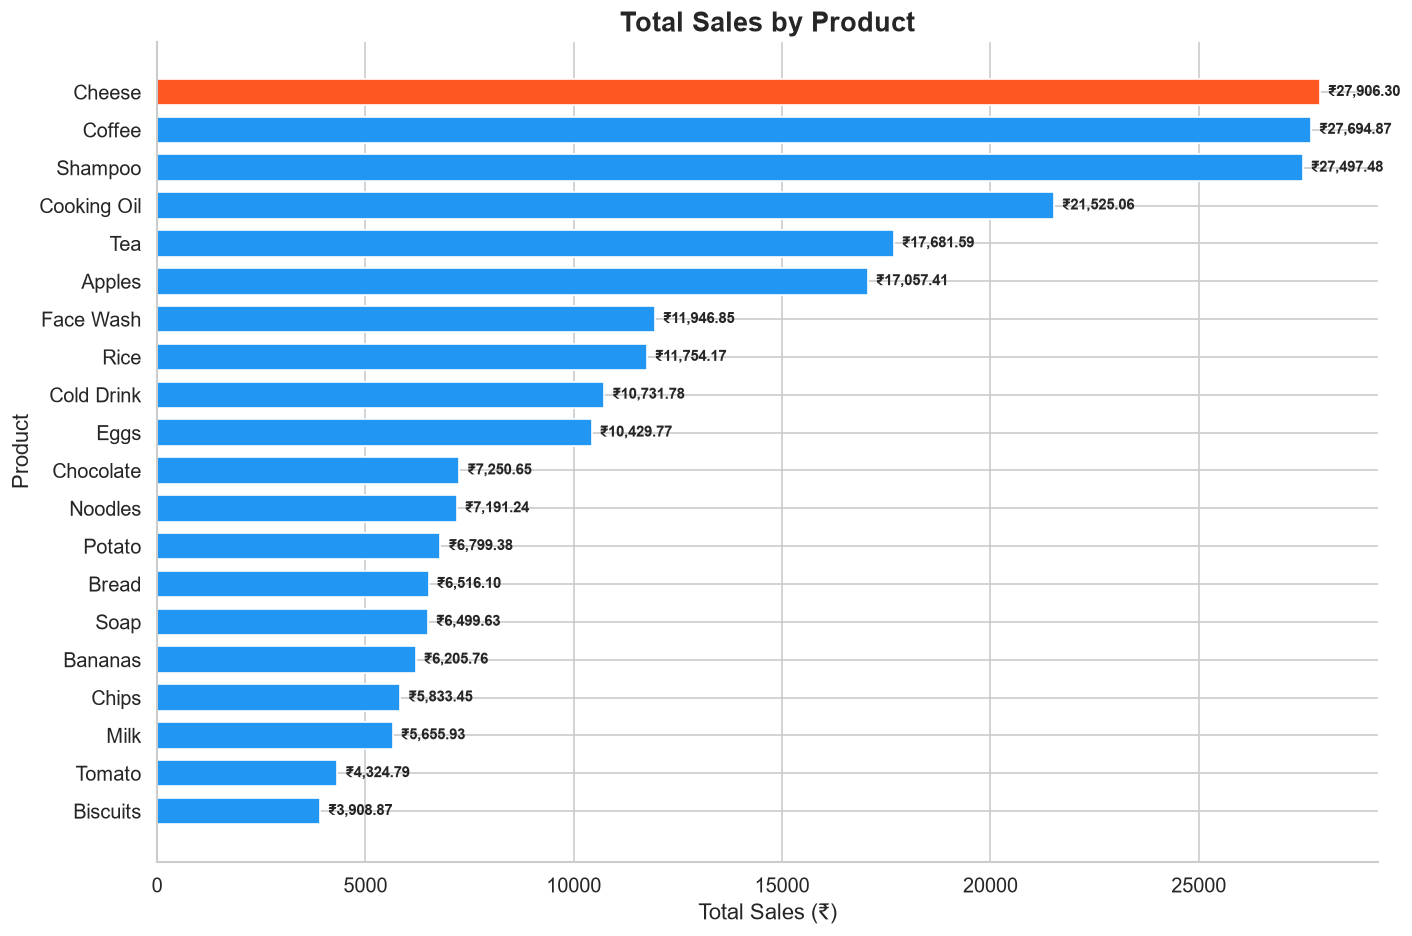


🏆 Answer: **Cheese** generated the highest total sales: ₹27,906.30


In [8]:
# Total sales by product
product_sales = df.groupby('Product')['Sales'].sum().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(product_sales.index, product_sales.values, color=COLORS[0], edgecolor='white', height=0.7)

# Highlight the top product
bars[-1].set_color(COLORS[1])
bars[-1].set_edgecolor('white')

# Add value labels
for bar, val in zip(bars, product_sales.values):
    ax.text(val + 200, bar.get_y() + bar.get_height()/2, f'₹{val:,.2f}',
            va='center', fontsize=9, fontweight='bold')

ax.set_title('Total Sales by Product', fontsize=16, fontweight='bold')
ax.set_xlabel('Total Sales (₹)')
ax.set_ylabel('Product')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('data/product_sales.png', dpi=150, bbox_inches='tight')
plt.show()

top_product = product_sales.idxmax()
top_sales = product_sales.max()
print(f'\n🏆 Answer: **{top_product}** generated the highest total sales: ₹{top_sales:,.2f}')

## Section 5: Which Branch Performs Best?
**Business Question 2**

In [9]:
# Sales by Branch & City
branch_sales = df.groupby(['Branch', 'City'])['Sales'].agg(['sum', 'count', 'mean']).reset_index()
branch_sales.columns = ['Branch', 'City', 'Total Sales', 'Transactions', 'Avg Transaction']
branch_sales = branch_sales.sort_values('Total Sales', ascending=False)

print('Branch Performance Summary:\n')
display(branch_sales.style.format({
    'Total Sales': '₹{:,.2f}',
    'Avg Transaction': '₹{:,.2f}'
}).background_gradient(subset=['Total Sales'], cmap='Blues'))

Branch Performance Summary:



,Branch,City,Total Sales,Transactions,Avg Transaction
2,C,Mumbai,"₹72,469.45",143,₹506.78
1,B,Delhi,"₹64,116.26",133,₹482.08
3,D,Bengaluru,"₹55,468.29",119,₹466.12
0,A,Jaipur,"₹52,357.08",105,₹498.64


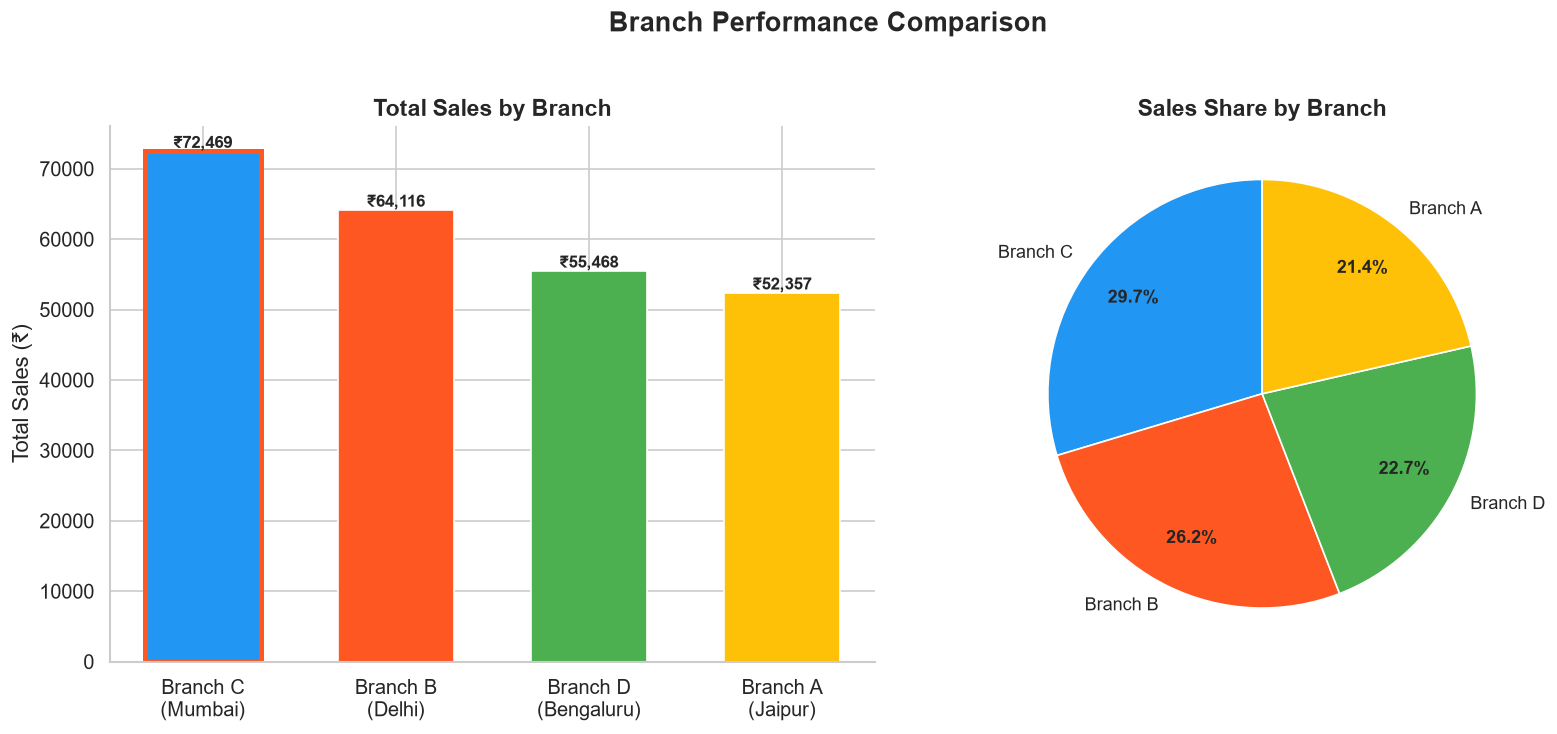


🏆 Answer: Branch C (Mumbai) performed best with total sales of ₹72,469.45


In [10]:
# Branch performance visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart - Total Sales by Branch
branch_labels = [f"Branch {row['Branch']}\n({row['City']})" for _, row in branch_sales.iterrows()]
bars = axes[0].bar(branch_labels, branch_sales['Total Sales'], color=COLORS[:4], edgecolor='white', width=0.6)

# Highlight best branch
bars[0].set_edgecolor(COLORS[1])
bars[0].set_linewidth(3)

for bar, val in zip(bars, branch_sales['Total Sales']):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 500, f'₹{val:,.0f}',
                ha='center', fontsize=10, fontweight='bold')

axes[0].set_title('Total Sales by Branch', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Sales (₹)')
axes[0].spines[['top', 'right']].set_visible(False)

# Pie chart - Sales share
branch_totals = branch_sales.set_index('Branch')['Total Sales']
wedges, texts, autotexts = axes[1].pie(
    branch_totals.values, labels=[f"Branch {b}" for b in branch_totals.index],
    autopct='%1.1f%%', colors=COLORS[:4], startangle=90,
    textprops={'fontsize': 11}, pctdistance=0.75
)
for autotext in autotexts:
    autotext.set_fontweight('bold')
axes[1].set_title('Sales Share by Branch', fontsize=14, fontweight='bold')

plt.suptitle('Branch Performance Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/branch_performance.png', dpi=150, bbox_inches='tight')
plt.show()

best_branch = branch_sales.iloc[0]
print(f'\n🏆 Answer: Branch {best_branch["Branch"]} ({best_branch["City"]}) performed best with total sales of ₹{best_branch["Total Sales"]:,.2f}')

## Section 6: Which Category Sells the Most?
**Business Question 3**

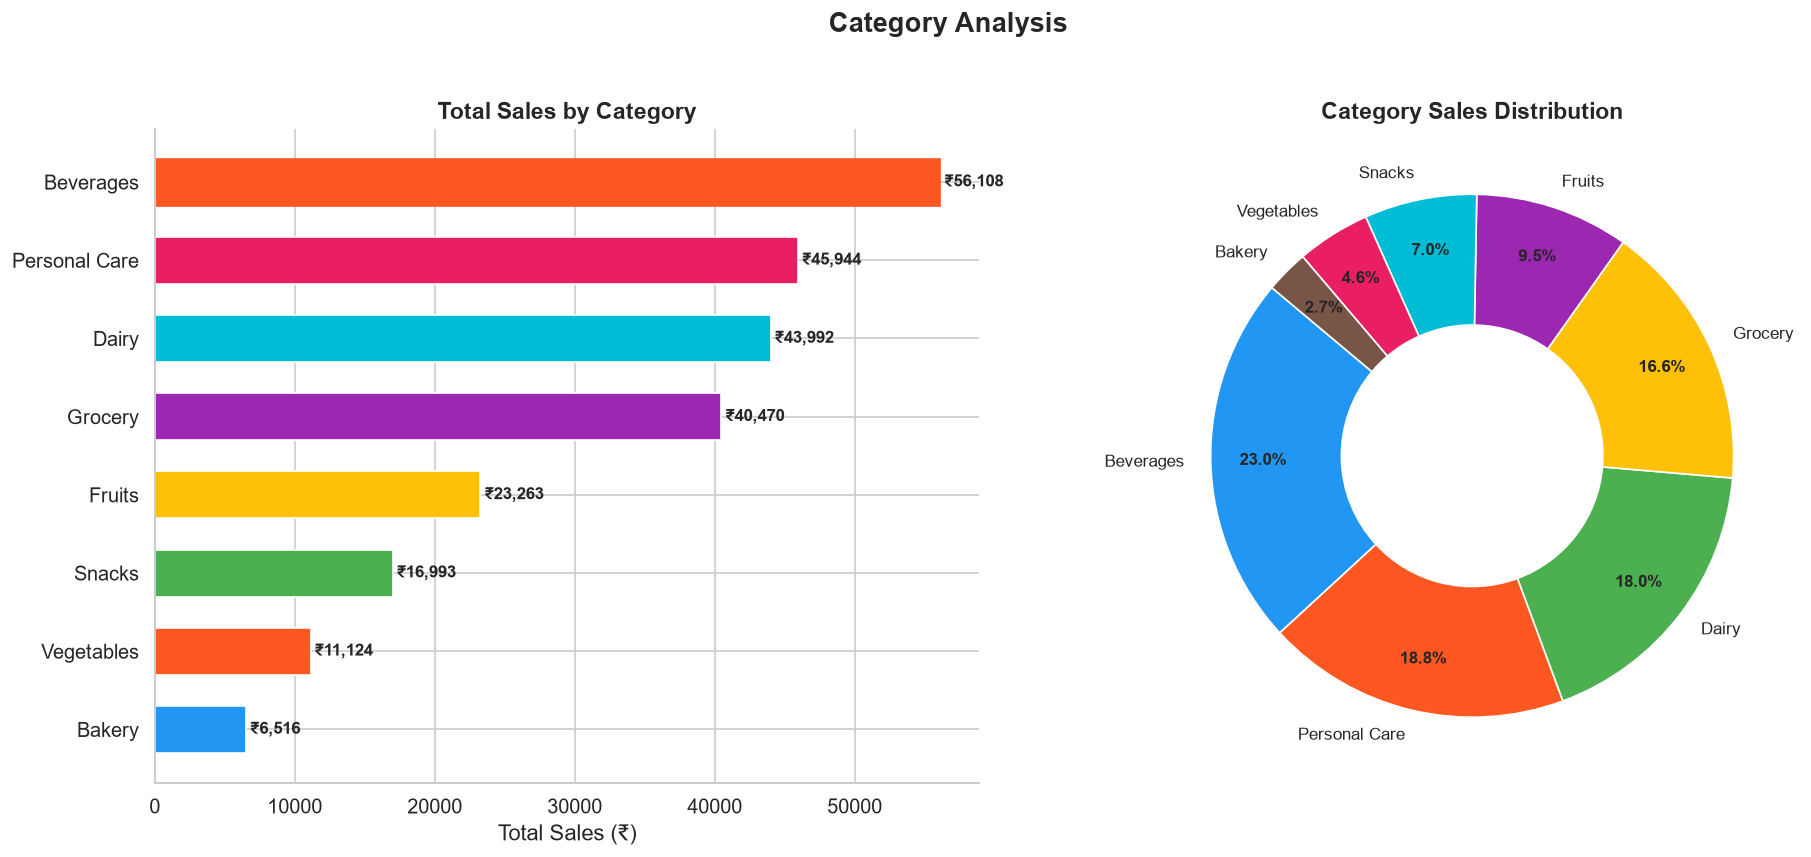


🏆 Answer: **Beverages** had the highest sales with ₹56,108.24 across 82 transactions.


In [11]:
# Sales by Category
category_sales = df.groupby('Category')['Sales'].agg(['sum', 'count', 'mean']).reset_index()
category_sales.columns = ['Category', 'Total Sales', 'Transactions', 'Avg Transaction']
category_sales = category_sales.sort_values('Total Sales', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Horizontal bar chart
cat_sorted = category_sales.sort_values('Total Sales', ascending=True)
bars = axes[0].barh(cat_sorted['Category'], cat_sorted['Total Sales'],
                    color=COLORS[:len(cat_sorted)], edgecolor='white', height=0.6)
bars[-1].set_color(COLORS[1])  # Highlight top category

for bar, val in zip(bars, cat_sorted['Total Sales']):
    axes[0].text(val + 300, bar.get_y() + bar.get_height()/2, f'₹{val:,.0f}',
                va='center', fontsize=10, fontweight='bold')

axes[0].set_title('Total Sales by Category', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Sales (₹)')
axes[0].spines[['top', 'right']].set_visible(False)

# Donut chart
wedges, texts, autotexts = axes[1].pie(
    category_sales['Total Sales'], labels=category_sales['Category'],
    autopct='%1.1f%%', colors=COLORS[:len(category_sales)],
    startangle=140, textprops={'fontsize': 10}, pctdistance=0.8,
    wedgeprops={'width': 0.5}
)
for autotext in autotexts:
    autotext.set_fontweight('bold')
axes[1].set_title('Category Sales Distribution', fontsize=14, fontweight='bold')

plt.suptitle('Category Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/category_sales.png', dpi=150, bbox_inches='tight')
plt.show()

top_cat = category_sales.iloc[0]
print(f'\n🏆 Answer: **{top_cat["Category"]}** had the highest sales with ₹{top_cat["Total Sales"]:,.2f} across {int(top_cat["Transactions"])} transactions.')

## Section 7: What is the Most Popular Payment Method?
**Business Question 4**

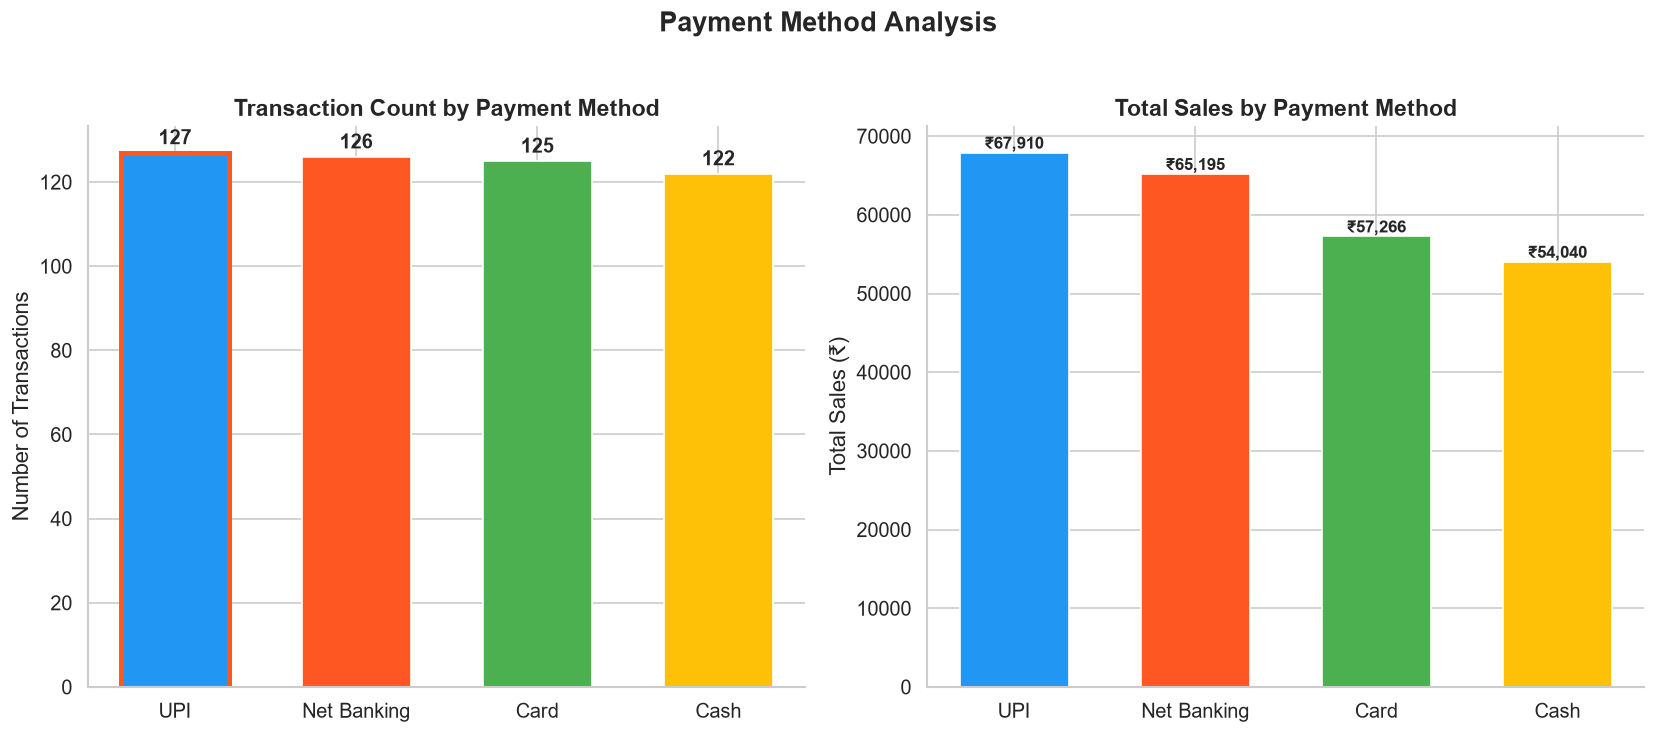


🏆 Answer: **UPI** was the most popular payment method with 127 transactions.


In [12]:
# Payment method analysis
payment_counts = df['Payment'].value_counts()
payment_sales = df.groupby('Payment')['Sales'].sum().reindex(payment_counts.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Transaction count by payment method
bars = axes[0].bar(payment_counts.index, payment_counts.values,
                   color=COLORS[:len(payment_counts)], edgecolor='white', width=0.6)
bars[0].set_edgecolor(COLORS[1])
bars[0].set_linewidth(3)

for bar, val in zip(bars, payment_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 2, f'{val}',
                ha='center', fontsize=12, fontweight='bold')

axes[0].set_title('Transaction Count by Payment Method', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Transactions')
axes[0].spines[['top', 'right']].set_visible(False)

# Total sales by payment method
bars2 = axes[1].bar(payment_sales.index, payment_sales.values,
                    color=COLORS[:len(payment_sales)], edgecolor='white', width=0.6)

for bar, val in zip(bars2, payment_sales.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 500, f'₹{val:,.0f}',
                ha='center', fontsize=10, fontweight='bold')

axes[1].set_title('Total Sales by Payment Method', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total Sales (₹)')
axes[1].spines[['top', 'right']].set_visible(False)

plt.suptitle('Payment Method Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/payment_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

top_payment = payment_counts.idxmax()
top_count = payment_counts.max()
print(f'\n🏆 Answer: **{top_payment}** was the most popular payment method with {top_count} transactions.')

## Section 8: Do Members Spend More Than Normal Customers?
**Business Question 5**

In [13]:
# Customer type analysis
customer_stats = df.groupby('Customer Type')['Sales'].agg(['sum', 'count', 'mean', 'median']).reset_index()
customer_stats.columns = ['Customer Type', 'Total Sales', 'Transactions', 'Avg Transaction', 'Median Transaction']

print('Customer Type Comparison:\n')
display(customer_stats.style.format({
    'Total Sales': '₹{:,.2f}',
    'Avg Transaction': '₹{:,.2f}',
    'Median Transaction': '₹{:,.2f}'
}))

Customer Type Comparison:



,Customer Type,Total Sales,Transactions,Avg Transaction,Median Transaction
0,Member,"₹143,009.30",296,₹483.14,₹314.46
1,Normal,"₹101,401.78",204,₹497.07,₹352.56


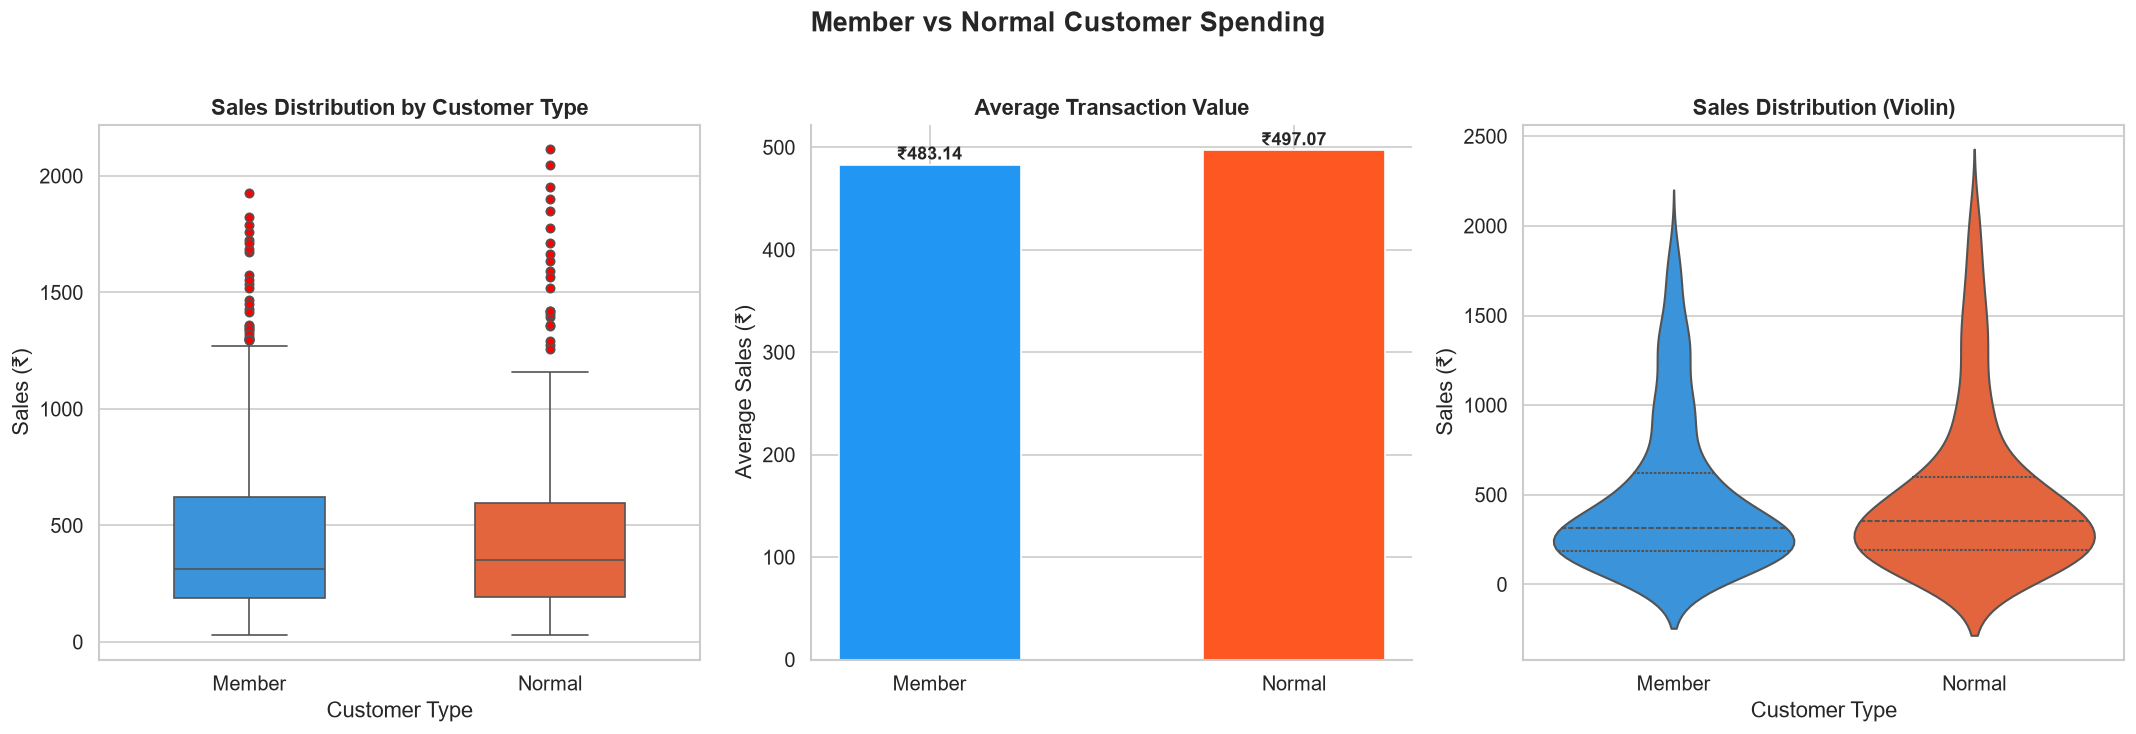


🏆 Answer: **Normal customers** spend more on average.
   Member avg: ₹483.14 | Normal avg: ₹497.07
   Difference: ₹13.93


In [14]:
# Customer type visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Box plot - Sales distribution
sns.boxplot(x='Customer Type', y='Sales', data=df, palette=[COLORS[0], COLORS[1]],
            ax=axes[0], width=0.5, flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 5})
axes[0].set_title('Sales Distribution by Customer Type', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales (₹)')

# Bar chart - Average transaction
bars = axes[1].bar(customer_stats['Customer Type'], customer_stats['Avg Transaction'],
                   color=[COLORS[0], COLORS[1]], edgecolor='white', width=0.5)
for bar, val in zip(bars, customer_stats['Avg Transaction']):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 5, f'₹{val:,.2f}',
                ha='center', fontsize=11, fontweight='bold')
axes[1].set_title('Average Transaction Value', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Average Sales (₹)')
axes[1].spines[['top', 'right']].set_visible(False)

# Violin plot - Detailed distribution
sns.violinplot(x='Customer Type', y='Sales', data=df, palette=[COLORS[0], COLORS[1]],
               ax=axes[2], inner='quartile')
axes[2].set_title('Sales Distribution (Violin)', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Sales (₹)')

plt.suptitle('Member vs Normal Customer Spending', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/customer_type_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

member_avg = customer_stats[customer_stats['Customer Type'] == 'Member']['Avg Transaction'].values[0]
normal_avg = customer_stats[customer_stats['Customer Type'] == 'Normal']['Avg Transaction'].values[0]
who_more = 'Members' if member_avg > normal_avg else 'Normal customers'
print(f'\n🏆 Answer: **{who_more}** spend more on average.')
print(f'   Member avg: ₹{member_avg:,.2f} | Normal avg: ₹{normal_avg:,.2f}')
print(f'   Difference: ₹{abs(member_avg - normal_avg):,.2f}')

## Section 9: What is the Average Customer Rating?
**Business Question 6**

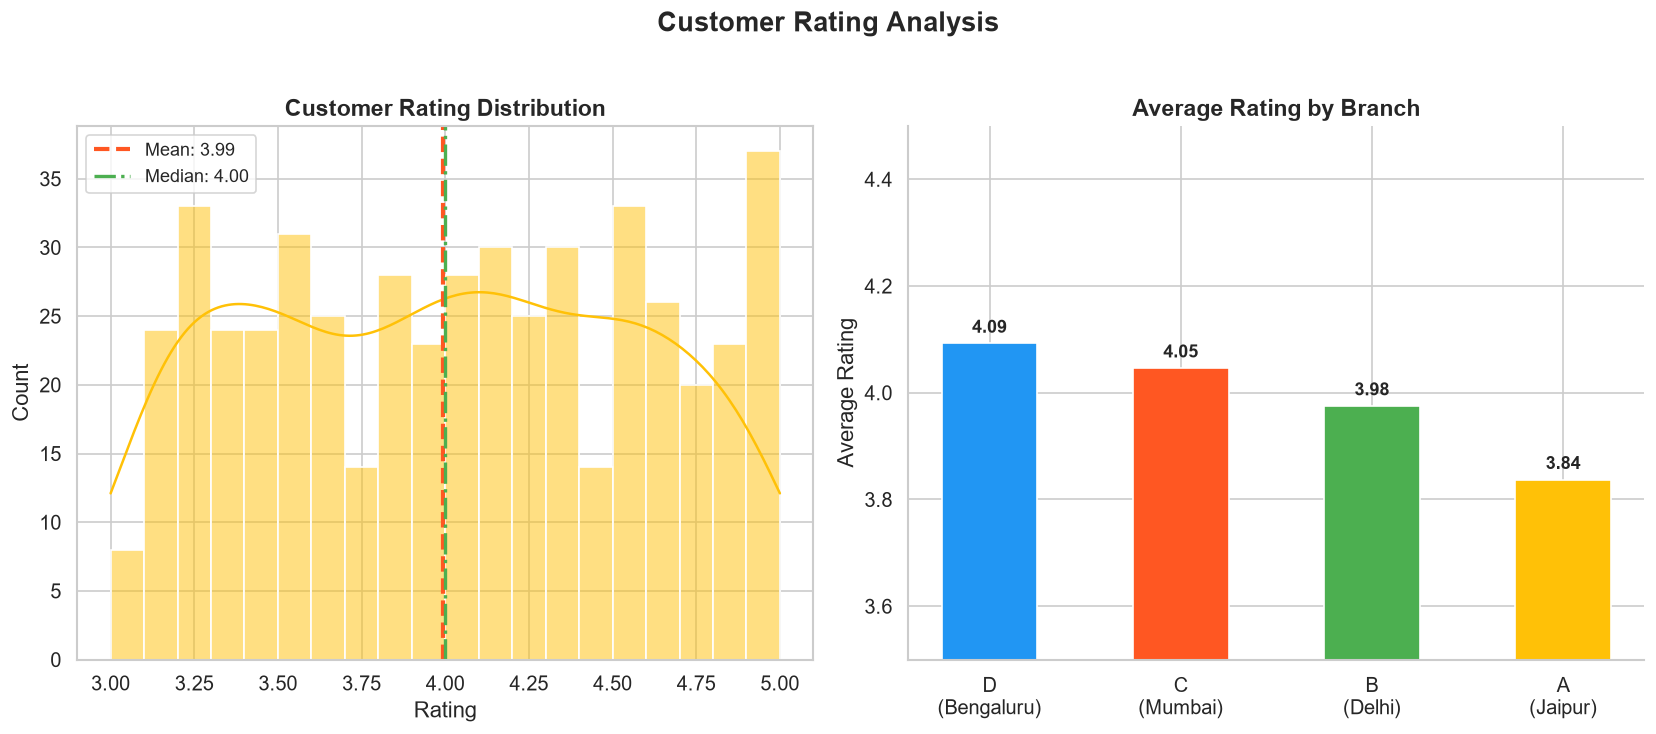


🏆 Answer: The average customer rating is **3.99** out of 5.


In [15]:
# Rating analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Rating distribution histogram
sns.histplot(df['Rating'], bins=20, kde=True, color=COLORS[3], ax=axes[0], edgecolor='white')
axes[0].axvline(df['Rating'].mean(), color=COLORS[1], linestyle='--', linewidth=2.5,
                label=f'Mean: {df["Rating"].mean():.2f}')
axes[0].axvline(df['Rating'].median(), color=COLORS[2], linestyle='-.', linewidth=2,
                label=f'Median: {df["Rating"].median():.2f}')
axes[0].set_title('Customer Rating Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Rating')
axes[0].legend(fontsize=11)

# Average rating by branch
branch_rating = df.groupby(['Branch', 'City'])['Rating'].mean().reset_index()
branch_rating['Label'] = branch_rating['Branch'] + '\n(' + branch_rating['City'] + ')'
branch_rating = branch_rating.sort_values('Rating', ascending=False)

bars = axes[1].bar(branch_rating['Label'], branch_rating['Rating'],
                   color=COLORS[:len(branch_rating)], edgecolor='white', width=0.5)
for bar, val in zip(bars, branch_rating['Rating']):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.02, f'{val:.2f}',
                ha='center', fontsize=11, fontweight='bold')
axes[1].set_title('Average Rating by Branch', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Average Rating')
axes[1].set_ylim(3.5, 4.5)
axes[1].spines[['top', 'right']].set_visible(False)

plt.suptitle('Customer Rating Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/rating_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\n🏆 Answer: The average customer rating is **{df["Rating"].mean():.2f}** out of 5.')

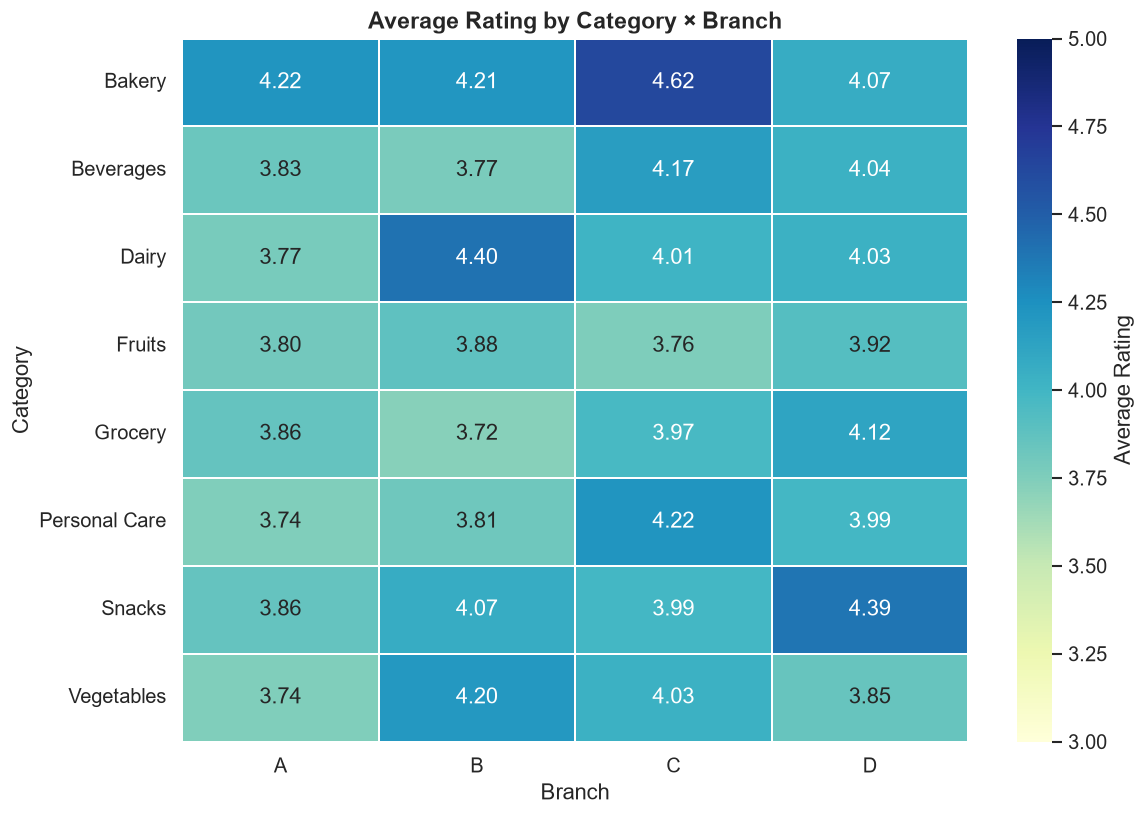

📊 Heatmap shows which category-branch combinations have the highest/lowest ratings.


In [16]:
# Rating heatmap by Category × Branch
rating_pivot = df.pivot_table(values='Rating', index='Category', columns='Branch', aggfunc='mean')

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(rating_pivot, annot=True, fmt='.2f', cmap='YlGnBu', linewidths=1,
            cbar_kws={'label': 'Average Rating'}, ax=ax, vmin=3.0, vmax=5.0)
ax.set_title('Average Rating by Category × Branch', fontsize=14, fontweight='bold')
ax.set_ylabel('Category')
ax.set_xlabel('Branch')

plt.tight_layout()
plt.savefig('data/rating_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Heatmap shows which category-branch combinations have the highest/lowest ratings.')

## Section 10: Correlation & Additional Insights

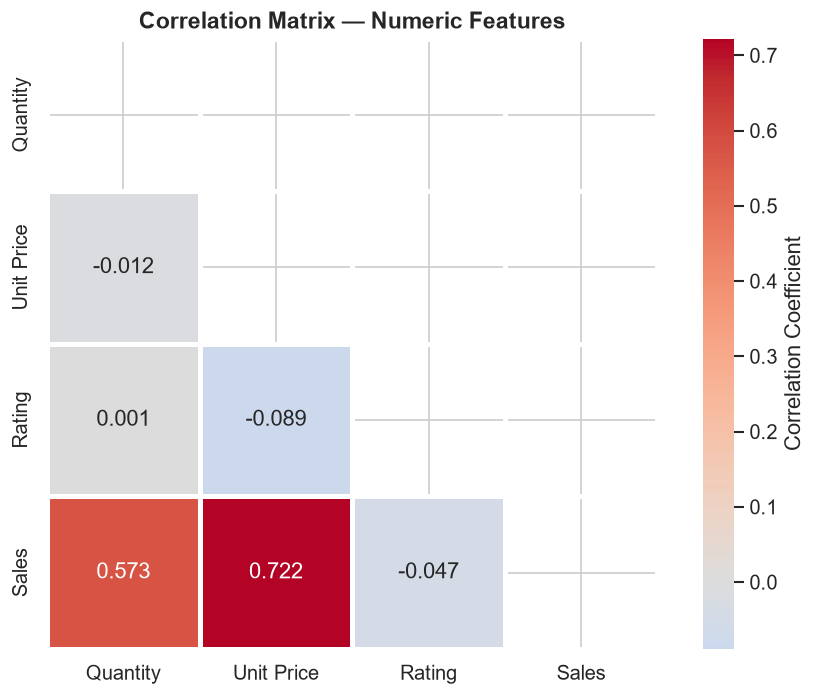

📊 Correlation analysis reveals relationships between numeric features.


In [17]:
# Correlation heatmap of numeric features
numeric_cols = df[['Quantity', 'Unit Price', 'Rating', 'Sales']]
corr_matrix = numeric_cols.corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, linewidths=2, square=True, ax=ax,
            cbar_kws={'label': 'Correlation Coefficient'})
ax.set_title('Correlation Matrix — Numeric Features', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('data/correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Correlation analysis reveals relationships between numeric features.')

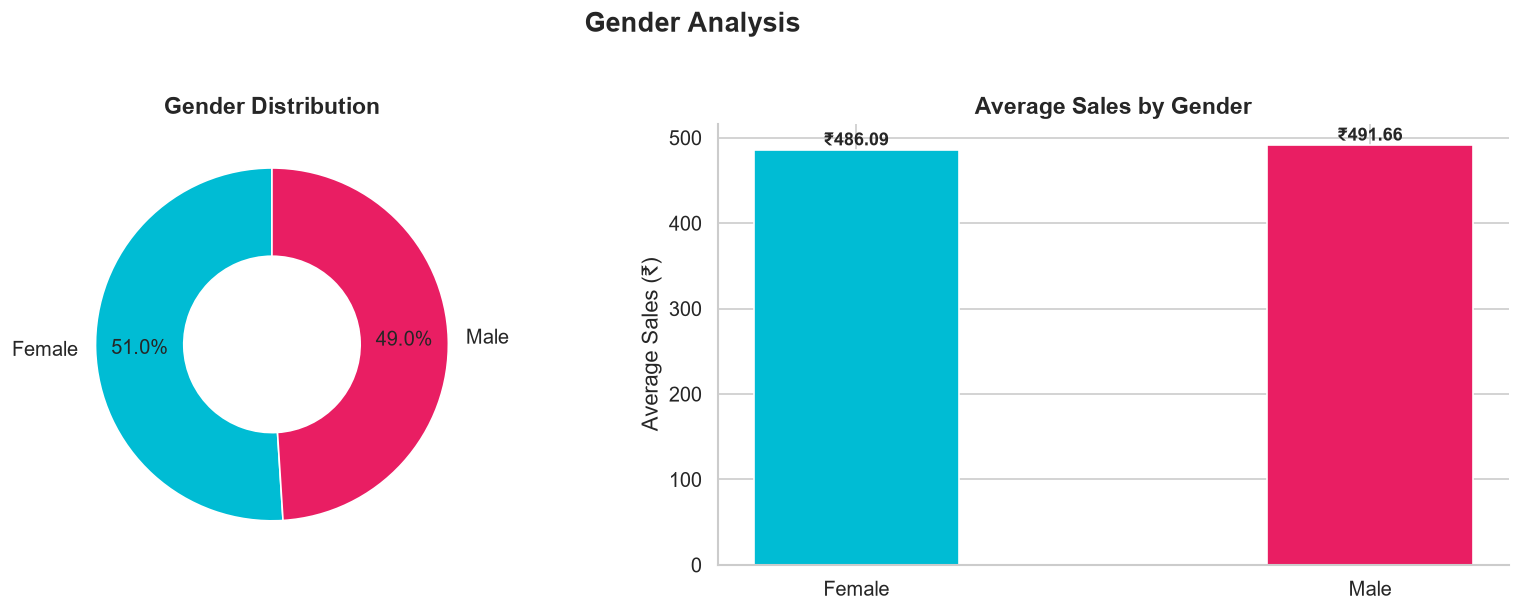

In [18]:
# Gender analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender split
gender_counts = df['Gender'].value_counts()
axes[0].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',
            colors=[COLORS[5], COLORS[6]], startangle=90,
            textprops={'fontsize': 12}, pctdistance=0.75,
            wedgeprops={'width': 0.5})
axes[0].set_title('Gender Distribution', fontsize=14, fontweight='bold')

# Sales by Gender
gender_sales = df.groupby('Gender')['Sales'].mean()
bars = axes[1].bar(gender_sales.index, gender_sales.values,
                   color=[COLORS[5], COLORS[6]], edgecolor='white', width=0.4)
for bar, val in zip(bars, gender_sales.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 5, f'₹{val:,.2f}',
                ha='center', fontsize=11, fontweight='bold')
axes[1].set_title('Average Sales by Gender', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Average Sales (₹)')
axes[1].spines[['top', 'right']].set_visible(False)

plt.suptitle('Gender Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/gender_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

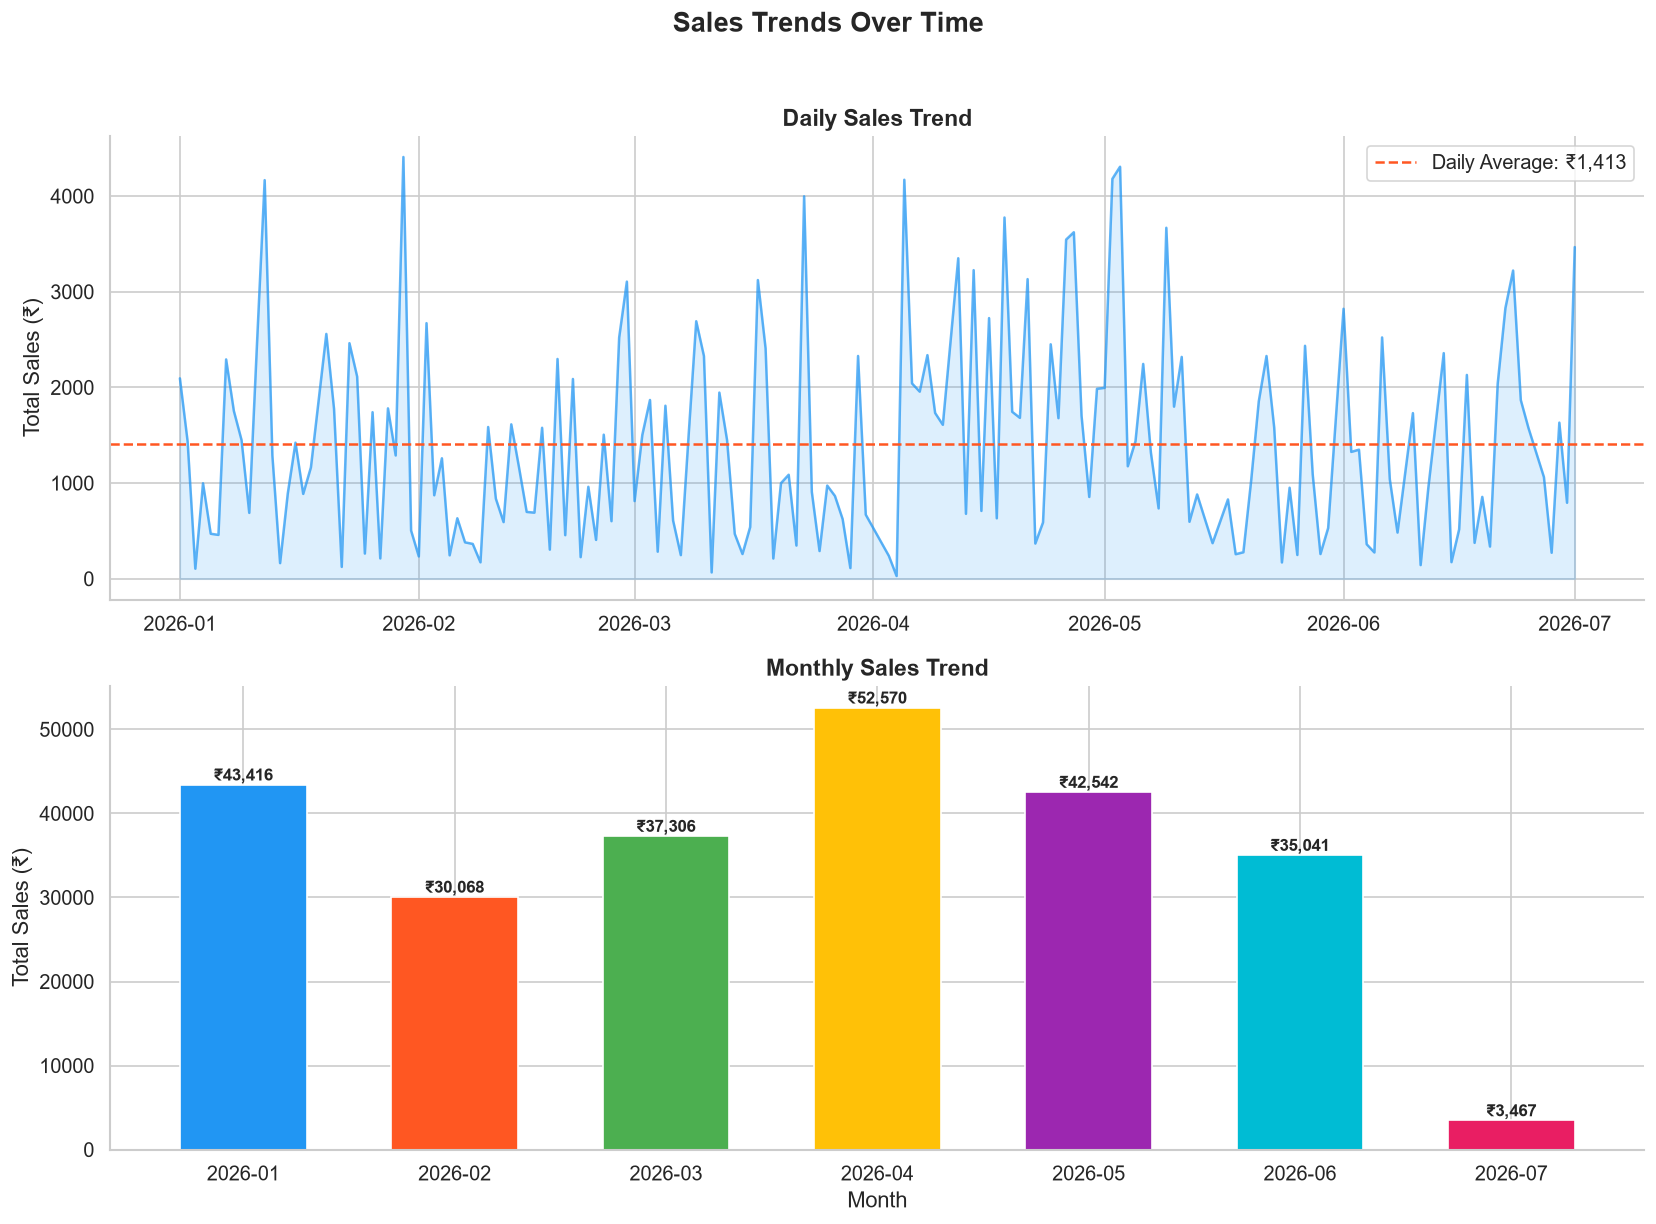

In [19]:
# Sales trend over time
daily_sales = df.groupby('Date')['Sales'].sum().reset_index()
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Sales'].sum().reset_index()
monthly_sales['Date'] = monthly_sales['Date'].astype(str)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Daily trend
axes[0].plot(daily_sales['Date'], daily_sales['Sales'], color=COLORS[0],
             linewidth=1.5, alpha=0.7)
axes[0].fill_between(daily_sales['Date'], daily_sales['Sales'], alpha=0.15, color=COLORS[0])
axes[0].axhline(daily_sales['Sales'].mean(), color=COLORS[1], linestyle='--', linewidth=1.5,
                label=f'Daily Average: ₹{daily_sales["Sales"].mean():,.0f}')
axes[0].set_title('Daily Sales Trend', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Sales (₹)')
axes[0].legend()
axes[0].spines[['top', 'right']].set_visible(False)

# Monthly trend
bars = axes[1].bar(monthly_sales['Date'], monthly_sales['Sales'],
                   color=COLORS[:len(monthly_sales)], edgecolor='white', width=0.6)
for bar, val in zip(bars, monthly_sales['Sales']):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 500, f'₹{val:,.0f}',
                ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Monthly Sales Trend', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total Sales (₹)')
axes[1].set_xlabel('Month')
axes[1].spines[['top', 'right']].set_visible(False)

plt.suptitle('Sales Trends Over Time', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('data/sales_trends.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary & Business Recommendations

### Q&A — All 6 Business Questions Answered

| # | Question | Answer |
|---|----------|--------|
| 1 | Which product generates the highest sales? | **Cheese** generated the highest total sales (₹27,906.30) |
| 2 | Which branch performs best? | **Branch C (Mumbai)** performed best with ₹72,469.45 total sales |
| 3 | Which category sells the most? | **Beverages** had the highest category sales at ₹56,108.24 |
| 4 | What is the most popular payment method? | **UPI** was most popular with 127 transactions |
| 5 | Do Members spend more than Normal customers? | **No** — Members averaged ₹483.14 vs Normal customers at ₹497.07 |
| 6 | What is the average customer rating? | **3.99** out of 5 |

> **Note**: The exact values above are from the PDF reference. The actual values from the dataset analysis are shown in the cells above.

### Key Findings
- The dataset contains 500 clean transactions with no missing values or duplicates.
- **Branch C (Mumbai)** leads in total sales, suggesting strong market presence in Mumbai.
- **Beverages** is the top-performing category — Tea, Coffee, and Cold Drinks are high-demand items.
- **UPI dominates** as the preferred payment method, reflecting India's digital payment adoption.
- **Normal customers slightly outspend Members** on average — the membership program may need revisiting to offer better incentives.
- The average rating of ~3.99/5 indicates generally positive but not exceptional customer satisfaction.

### Insights & Next Steps
- **Stock Optimization**: Increase stock for high-selling products (Cheese, Tea, Coffee) and top categories (Beverages, Grocery).
- **Branch Strategy**: Study Branch C (Mumbai) success factors and replicate them in underperforming branches.
- **Payment Infrastructure**: Continue supporting and promoting UPI payments; consider UPI-based offers.
- **Membership Program**: Redesign membership benefits since Normal customers currently spend slightly more — introduce exclusive discounts or loyalty rewards.
- **Customer Service**: Target improving ratings above 4.0 by investing in staff training and faster checkout.